# 06 · PINN: problema inverso

Estimar $\alpha, \beta, \gamma, K$ a partir de trayectorias $x(t)$, $\theta(t)$ simuladas con valores conocidos. Pérdida = ajuste a datos + residuo de las ecuaciones (Raissi et al., 2019). Configuración y tolerancia en `configs/pinn.yaml`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
TOPO_LABEL = {"erdos_renyi": "Erdős–Rényi", "barabasi_albert": "Barabási–Albert",
              "core_periphery": "Núcleo-periferia"}

In [2]:
from finnet.config import load_config
from finnet.ml.pinn import run_from_config

cfg = load_config("pinn.yaml")
res = run_from_config(cfg)
tab = pd.DataFrame({"real": res["true"], "estimado": {k: res["estimate"][k] for k in res["true"]},
                    "error relativo": res["relative_error"]})
tab.round(3)

/Users/ofi/Documents/Universidad/finnet/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,real,estimado,error relativo
alpha,0.80,0.859,0.074
beta,0.15,0.185,0.234
gamma,0.30,0.302,0.007
K,1.50,1.506,0.004


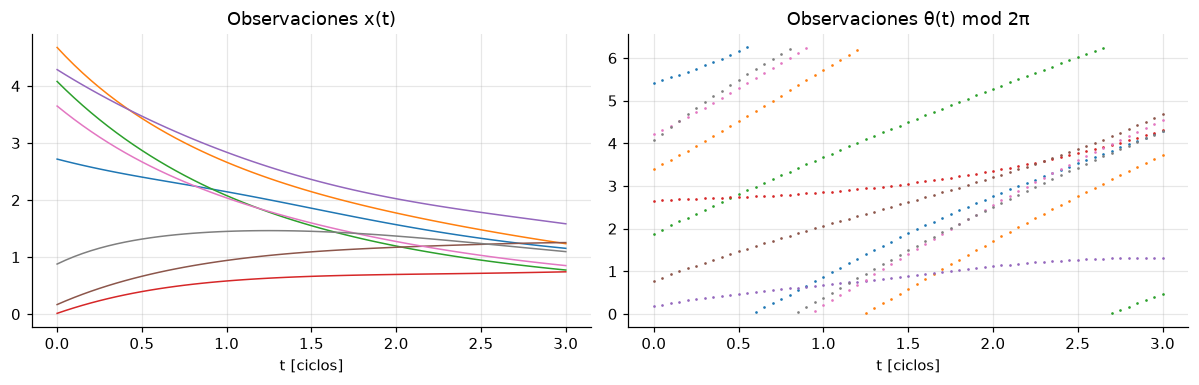

In [3]:
prob = res["problem"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(prob["t"], prob["x"], lw=1); ax[0].set(title="Observaciones x(t)", xlabel="t [ciclos]")
ax[1].plot(prob["t"], np.mod(prob["theta"], 2*np.pi), ".", ms=1.5); ax[1].set(title="Observaciones θ(t) mod 2π", xlabel="t [ciclos]")
fig.tight_layout(); fig.savefig(FIG / "fase6_pinn_datos.png")

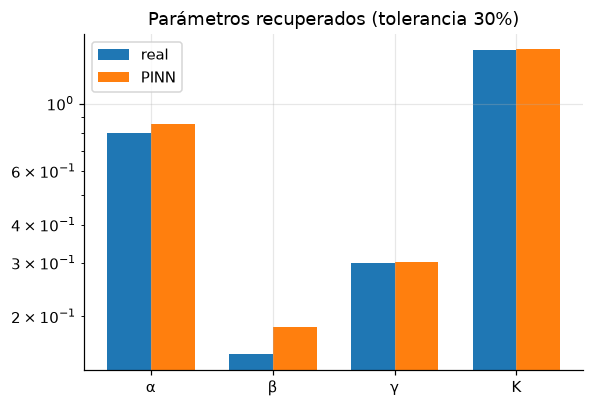

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
names = list(res["true"]); xx = np.arange(len(names))
ax.bar(xx - 0.18, [res["true"][k] for k in names], 0.36, label="real")
ax.bar(xx + 0.18, [res["estimate"][k] for k in names], 0.36, label="PINN")
ax.set_xticks(xx, ["α", "β", "γ", "K"]); ax.set_yscale("log"); ax.legend()
ax.set_title(f"Parámetros recuperados (tolerancia {cfg['tolerance']:.0%})")
fig.tight_layout(); fig.savefig(FIG / "fase6_pinn_parametros.png")